# Entrenamiento de los modelos YOLO

Entrena los dos detectores del proyecto con `src/train/train.py` y la configuración común `configs/train_base.yaml`:

| Modelo | Datos | Entregables |
|---|---|---|
| `full_yolov8s` | CCT completo (`data_full.yaml`) | E1, E2, E4, E5 |
| `eccv_yolov8s` | Partición oficial ECCV (`data_eccv.yaml`) | E3 |

Las corridas se guardan en Drive (`MyDrive/redes-parcial-p3/runs/`) para no perderlas si se cierra la sesión y poder reanudarlas.

Usar un entorno con GPU **L4** o **A100** (más disco y más rápido que la T4).

## Preparar la máquina

Cada notebook de Colab corre en su propia máquina, así que primero se ejecuta `colab_setup.ipynb` completo: monta Drive, clona el repo, instala dependencias, extrae las imágenes y genera las etiquetas YOLO. La extracción de los 105 GB tarda bastante.

In [10]:
import os
from google.colab import drive

drive.mount('/content/drive')
REPO_DIR = '/content/redes-parcial-p3'
if not os.path.isdir(REPO_DIR):
    !git clone https://github.com/Roxana-Vargas/redes-parcial-p3.git {REPO_DIR}
%cd {REPO_DIR}
!git pull
%run notebooks/colab_setup.ipynb

Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Setup complete ✅ (12 CPUs, 53.0 GB RAM, 42.6/235.7 GB disk)
cct_images.tar.gz ya está completo en Drive.
Disco libre en /content: 207 GB
Extrayendo desde LILA...
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
31
32
33
34
35
36
37
38
39
40
41
42
43
44
44
45
46
47
48
49
50
51
52
53
53
54
55
56
57
58
59
60
61
62
63
64
65
66
66
67
68
69
70
71
72
72
73
74
75
76
77
78
79
80
81
81
82
83
84
85
86
87
88
88
89
90
91
92
93
94
95
96
97
98
99
100
Marcador EOI agregado a 186,720 de 244,584 imágenes
189M	/content/redes-parcial-p3/data/raw/annotations
106G	/content/redes-parcial-p3/data/raw/cct_images
Imágenes .jpg: 244,584
Anotaciones JSON:
   annotations/CaltechCameraTrapsSplits_v0.json
   annotations/caltech_bboxes_20200316.json
   annotations/caltech_images_20210113.json
   annotations/eccv_18_annotation_files/cis_test_annotations.json
   annotations/eccv_18_annotation_files/

In [11]:
PROJECT = ' /content/drive/MyDrive/redes-parcial-p3/runs'
!cat configs/train_base.yaml

# Hiperparámetros comunes al modelo principal y al modelo E3.
# Justificación de cada valor en docs/decisiones_entrenamiento.md

imgsz: 640
epochs: 40
patience: 10          # early stopping si el mAP de validación no mejora en 10 épocas
batch: -1             # autobatch: el mayor batch que cabe en ~60 % de la VRAM de la GPU
optimizer: auto
seed: 0
deterministic: true
workers: 8
close_mosaic: 10      # desactiva mosaic en las últimas 10 épocas
plots: true

# Aumento de datos
hsv_h: 0.015
hsv_s: 0.7
hsv_v: 0.4
degrees: 0.0
translate: 0.1
scale: 0.5
shear: 0.0
perspective: 0.0
fliplr: 0.5
flipud: 0.0
mosaic: 1.0
mixup: 0.0


## Corrida de prueba

Una época con el 2 % del train, para verificar que los datos, las etiquetas y la GPU funcionan antes de lanzar el entrenamiento largo. Si falla aquí, no se pierden horas de GPU.

In [ ]:
!python src/train/train.py --data data/yolo/data_full.yaml --name prueba --project {PROJECT} --epochs 1 --fraction 0.02

Streaming output truncated to the last 5000 lines.
val: /content/redes-parcial-p3/data/yolo/images/59dc2813-23d2-11e8-a6a3-ec086b02610b.jpg: corrupt JPEG restored and saved
val: /content/redes-parcial-p3/data/yolo/images/59dc2816-23d2-11e8-a6a3-ec086b02610b.jpg: corrupt JPEG restored and saved
val: /content/redes-parcial-p3/data/yolo/images/59dc2817-23d2-11e8-a6a3-ec086b02610b.jpg: corrupt JPEG restored and saved
val: /content/redes-parcial-p3/data/yolo/images/59ddbf8a-23d2-11e8-a6a3-ec086b02610b.jpg: corrupt JPEG restored and saved
val: /content/redes-parcial-p3/data/yolo/images/59ddbf8b-23d2-11e8-a6a3-ec086b02610b.jpg: corrupt JPEG restored and saved
val: /content/redes-parcial-p3/data/yolo/images/59ddbf8f-23d2-11e8-a6a3-ec086b02610b.jpg: corrupt JPEG restored and saved
val: /content/redes-parcial-p3/data/yolo/images/59ddbfa2-23d2-11e8-a6a3-ec086b02610b.jpg: corrupt JPEG restored and saved
val: /content/redes-parcial-p3/data/yolo/images/59ddbfaa-23d2-11e8-a6a3-ec086b02610b.jpg: corru

## Modelo principal (CCT completo)

Entrenamiento largo: unas 113k imágenes por época (83 % vacías). Revisar de vez en cuando que la sesión siga activa.

In [ ]:
!python src/train/train.py --data data/yolo/data_full.yaml --name full_yolov8s --project {PROJECT}

## Modelo E3 (partición oficial ECCV)

Misma configuración, entrenado solo con `eccv_train` (unas 11k imágenes). Se valida en `eccv_cis_val`.

In [ ]:
!python src/train/train.py --data data/yolo/data_eccv.yaml --name eccv_yolov8s --project {PROJECT}

## Reanudar una corrida cortada

Si la sesión de Colab se desconecta a mitad del entrenamiento, volver a preparar la máquina (primera celda) y reanudar desde el último checkpoint guardado en Drive. Cambiar `RUN` por la corrida que se cortó.

In [ ]:
RUN = 'full_yolov8s'
!python src/train/train.py --name {RUN} --project {PROJECT} --resume

## Curvas de entrenamiento

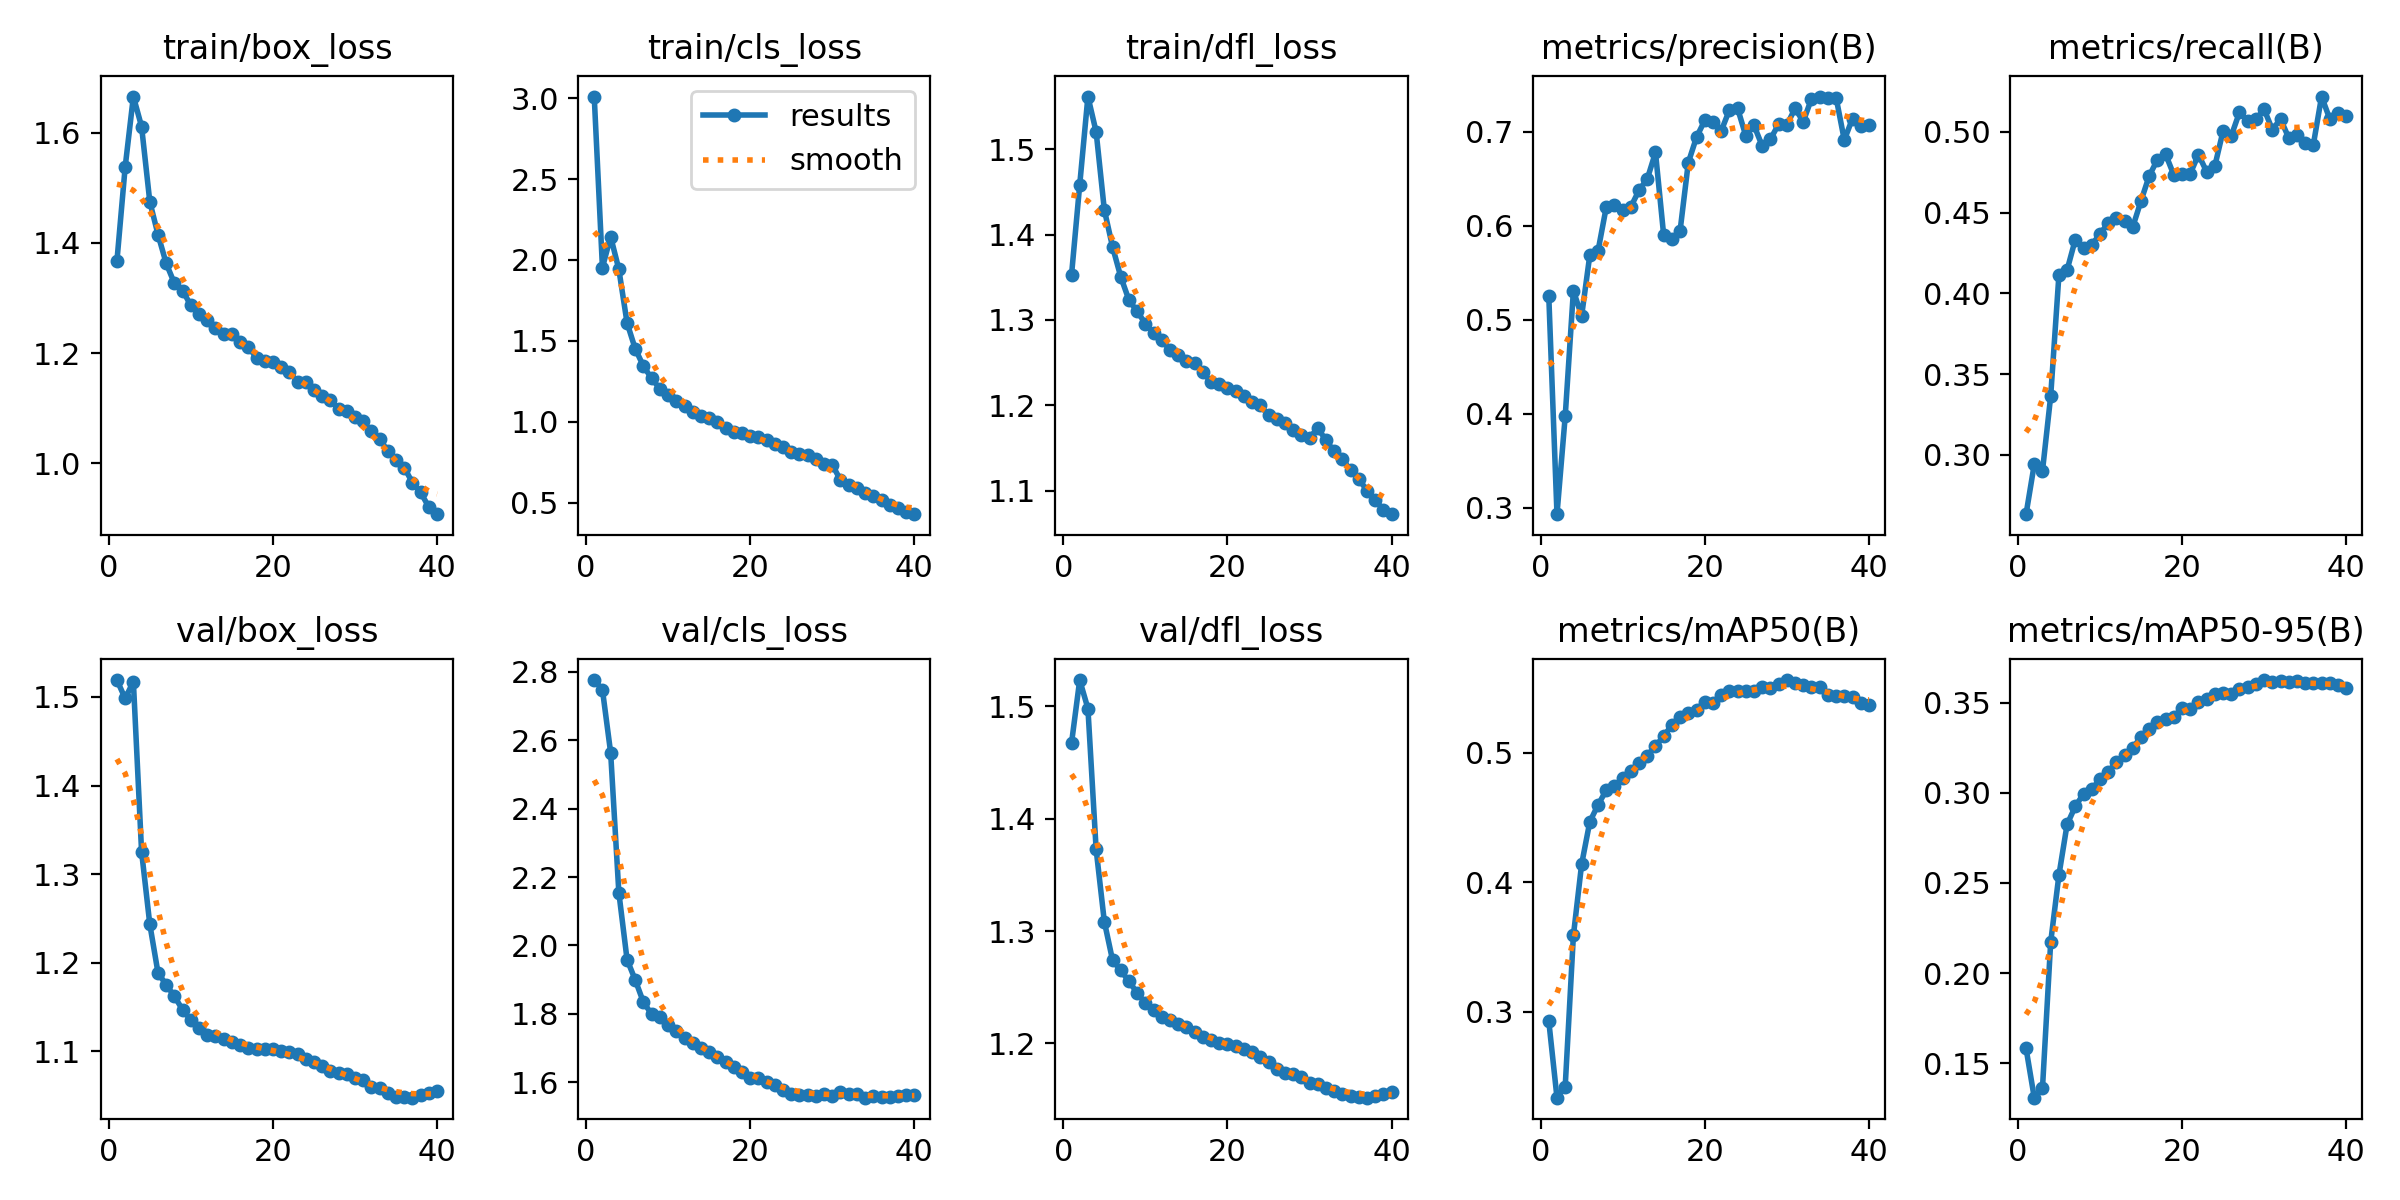

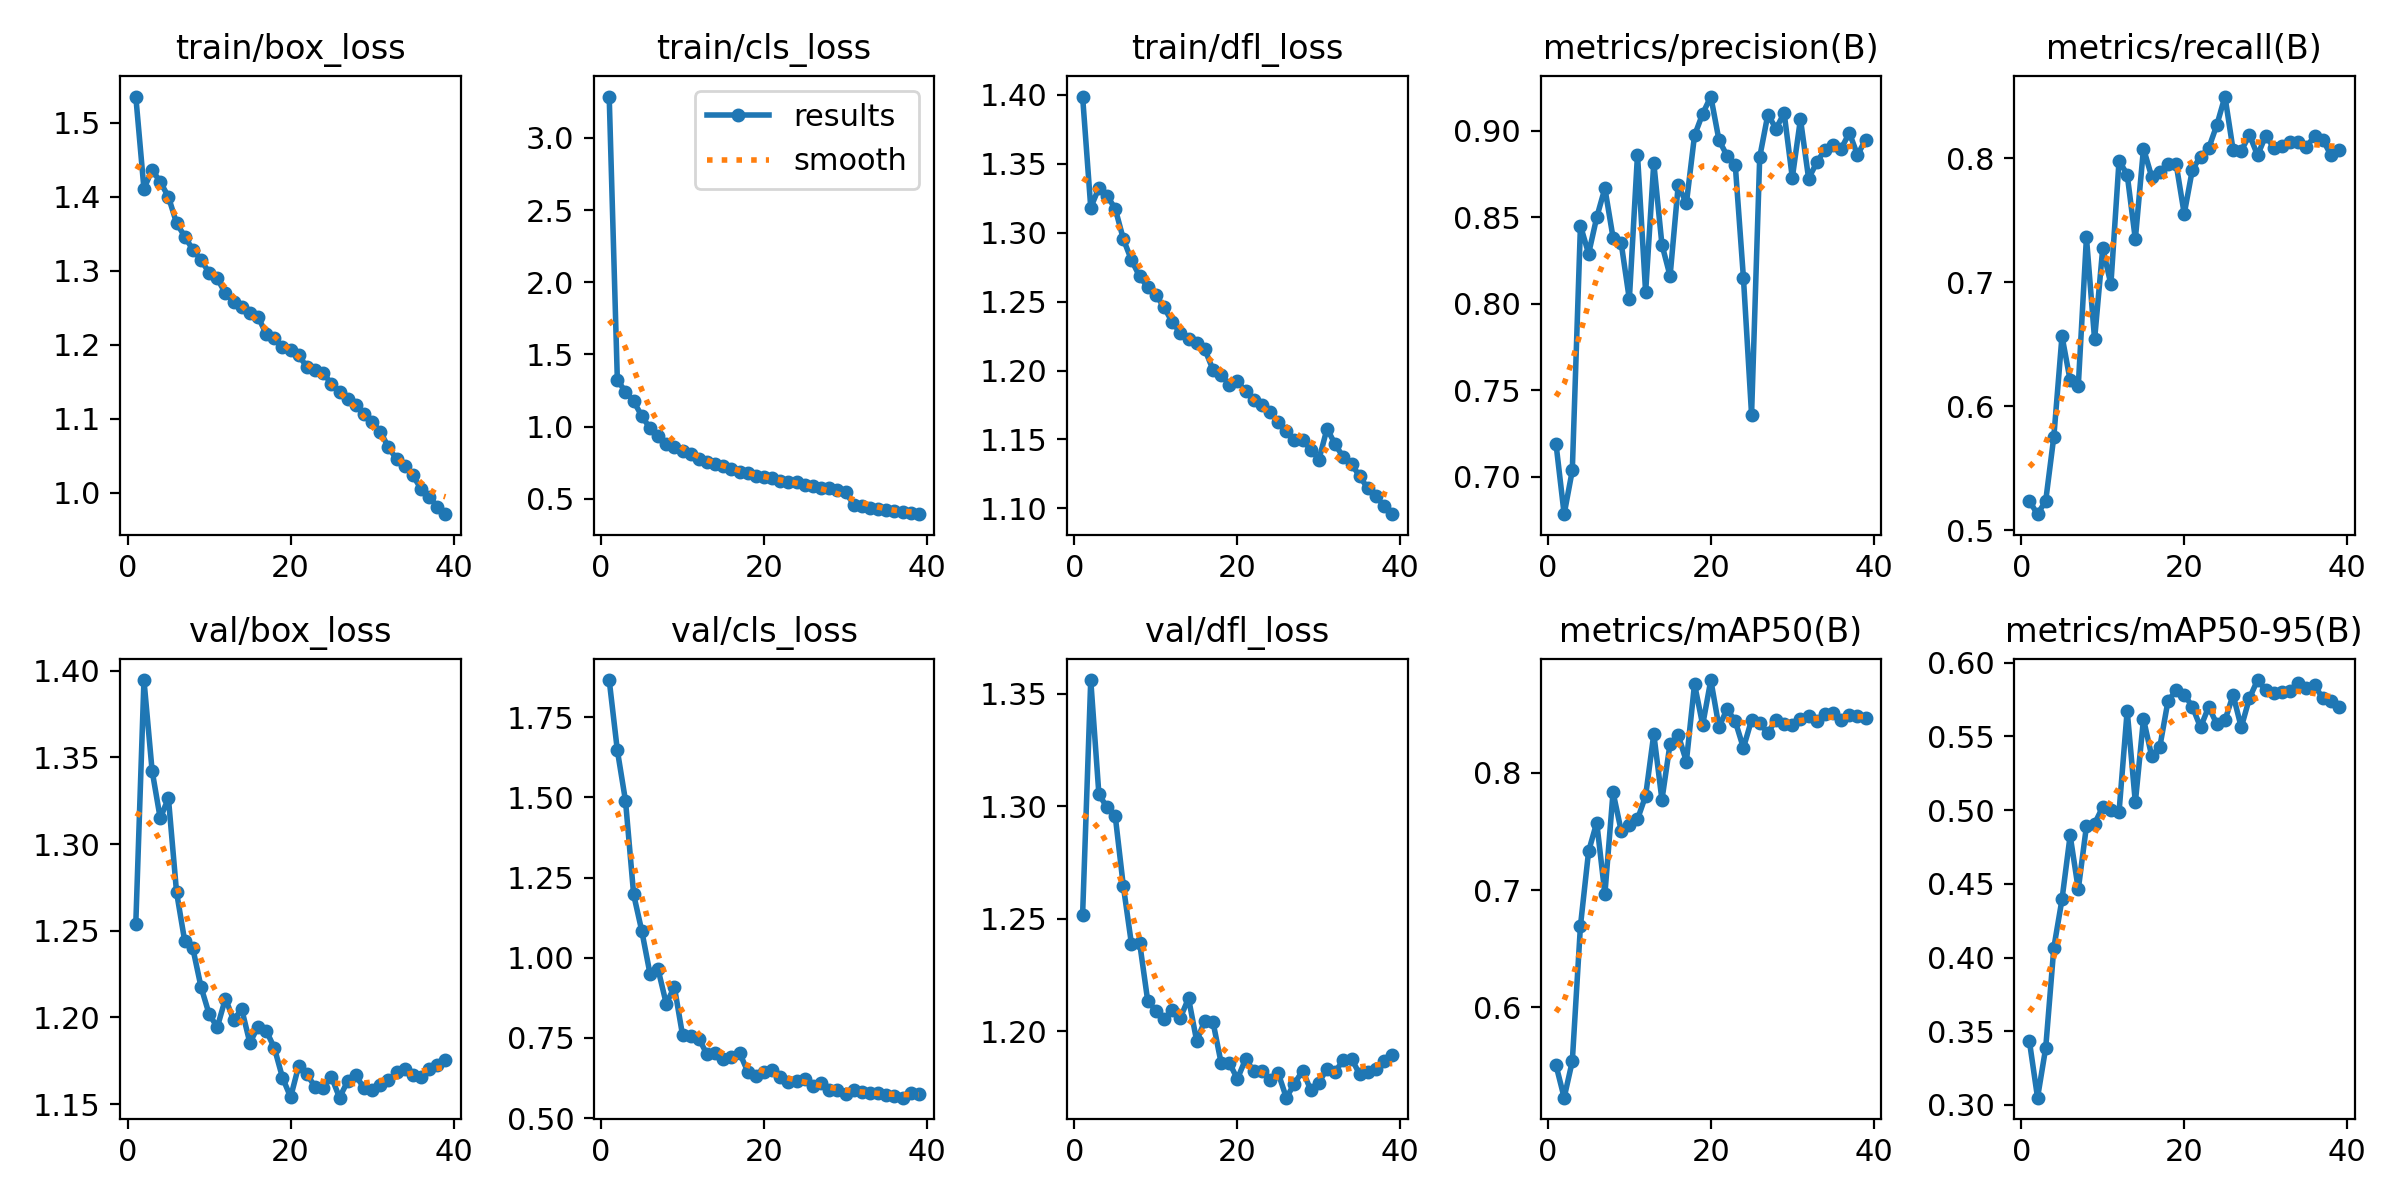

In [12]:
from IPython.display import Image, display
for run in ['full_yolov8s', 'eccv_yolov8s']:
    display(Image(f'/content/drive/MyDrive/redes-parcial-p3/runs/{run}/results.png', width=900))

## Evaluación y análisis

In [13]:
%cd /content/redes-parcial-p3
!git pull
!pip install -q pycocotools
D = '/content/drive/MyDrive/redes-parcial-p3'

/content/redes-parcial-p3
remote: Enumerating objects: 57, done.
remote: Counting objects: 100% (56/56), done.
remote: Compressing objects: 100% (35/35), done.
remote: Total 46 (delta 13), reused 44 (delta 11), pack-reused 0 (from 0)
Unpacking objects: 100% (46/46), 3.31 MiB | 16.04 MiB/s, done.
From https://github.com/Roxana-Vargas/redes-parcial-p3
   b100a21..d131c27  main       -> origin/main
Updating b100a21..d131c27
Fast-forward
 docs/decisiones_entrenamiento.md                   |    9 +-
 requirements.txt                                   |    1 +
 results/entrenamiento/eccv_yolov8s/BoxPR_curve.png |  Bin 0 -> 242070 bytes
 results/entrenamiento/eccv_yolov8s/args.yaml       |  114 +
 .../eccv_yolov8s/confusion_matrix_normalized.png   |  Bin 0 -> 307891 bytes
 results/entrenamiento/eccv_yolov8s/results.csv     |   40 +
 results/entrenamiento/eccv_yolov8s/results.png     |  Bin 0 -> 293094 bytes
 .../eccv_yolov8s/val_batch0_labels.jpg             |  Bin 0 -> 514849 bytes
 .../entr

### Métricas en test (E2 y E3)

In [14]:
evals = [('full_yolov8s', 'data/yolo/data_full.yaml', ['full_test', 'eccv_cis_test', 'eccv_trans_test']),
         ('eccv_yolov8s', 'data/yolo/data_eccv.yaml', ['eccv_cis_test', 'eccv_trans_test'])]
for model, data, splits in evals:
    for s in splits:
        !python src/eval/evaluate.py --weights {D}/runs/{model}/weights/best.pt --data {data} --split {s} --model {model} --project {D}/eval
!cat results/eval_summary.csv


Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 72 layers, 11,131,776 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 530.5±956.5 MB/s, size: 331.5 KB)
val: Scanning /content/redes-parcial-p3/data/yolo/labels... 43292 images, 19892 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 43292/43292 1.4Kit/s 31.3s
val: New cache created: /content/redes-parcial-p3/data/yolo/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1353/1353 4.8it/s 4:44
                   all      43292      24662      0.711      0.451      0.481       0.31
                badger         16         18          1          0     0.0189     0.0129
                  bird        956       1291      0.632      0.148      0.156     0.0899
                bobcat       2742       2844      0.798      0.579      0.683      0.448
                   cat       1304       

### Tamaño de la caja (E4)

In [17]:
!git pull
!python src/robustness/size_eval.py --pred {D}/eval/full_yolov8s_full_test/predictions.json --split full_test --model full_yolov8s

remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 5 (delta 3), reused 5 (delta 3), pack-reused 0 (from 0)
Unpacking objects: 100% (5/5), 548 bytes | 548.00 KiB/s, done.
From https://github.com/Roxana-Vargas/redes-parcial-p3
   d131c27..f9dd4da  main       -> origin/main
Updating d131c27..f9dd4da
Fast-forward
 src/robustness/size_eval.py | 3 ++-
 1 file changed, 2 insertions(+), 1 deletion(-)
Límites de tamaño (terciles de full_train): 1.91% y 4.59% del área de la imagen
43,292 imágenes, 24,662 cajas reales, 215,905 predicciones
  todas    24,662 cajas   mAP@0.5 = 0.481   mAP@0.5:0.95 = 0.311
  pequeña   8,242 cajas   mAP@0.5 = 0.372   mAP@0.5:0.95 = 0.204
  mediana   8,395 cajas   mAP@0.5 = 0.513   mAP@0.5:0.95 = 0.331
  grande    8,025 cajas   mAP@0.5 = 0.494   mAP@0.5:0.95 = 0.363


### EigenCAM (E3)

In [18]:
for model in ['eccv_yolov8s', 'full_yolov8s']:
    !python src/eval/eigencam.py --weights {D}/runs/{model}/weights/best.pt --model {model}

  eccv_cis_test: 100/500
  eccv_cis_test: 200/500
  eccv_cis_test: 300/500
  eccv_cis_test: 400/500
  eccv_cis_test: 500/500
eccv_cis_test    todas          n= 500  energía en caja=0.0699  área=0.0524  concentración=0.944  máximo en caja=0.0540
eccv_cis_test    detectadas     n= 432  energía en caja=0.0554  área=0.0405  concentración=0.879  máximo en caja=0.0394
eccv_cis_test    no_detectadas  n=  68  energía en caja=0.1621  área=0.1277  concentración=1.141  máximo en caja=0.1471
  eccv_trans_test: 100/500
  eccv_trans_test: 200/500
  eccv_trans_test: 300/500
  eccv_trans_test: 400/500
  eccv_trans_test: 500/500
eccv_trans_test  todas          n= 500  energía en caja=0.0960  área=0.0645  concentración=0.943  máximo en caja=0.0920
eccv_trans_test  detectadas     n= 342  energía en caja=0.0535  área=0.0362  concentración=0.707  máximo en caja=0.0409
eccv_trans_test  no_detectadas  n= 158  energía en caja=0.1881  área=0.1259  concentración=1.058  máximo en caja=0.2025
  eccv_cis_test: 100

In [20]:
!python src/eval/eigencam.py --weights {D}/runs/eccv_yolov8s/weights/best.pt --model eccv_yolov8s_capa15 --layer 15

  eccv_cis_test: 100/500
  eccv_cis_test: 200/500
  eccv_cis_test: 300/500
  eccv_cis_test: 400/500
  eccv_cis_test: 500/500
eccv_cis_test    todas          n= 500  energía en caja=0.0629  área=0.0524  concentración=0.807  máximo en caja=0.0240
eccv_cis_test    detectadas     n= 432  energía en caja=0.0535  área=0.0405  concentración=0.819  máximo en caja=0.0208
eccv_cis_test    no_detectadas  n=  68  energía en caja=0.1229  área=0.1277  concentración=0.638  máximo en caja=0.0441
  eccv_trans_test: 100/500
  eccv_trans_test: 200/500
  eccv_trans_test: 300/500
  eccv_trans_test: 400/500
  eccv_trans_test: 500/500
eccv_trans_test  todas          n= 500  energía en caja=0.0997  área=0.0645  concentración=0.964  máximo en caja=0.0660
eccv_trans_test  detectadas     n= 342  energía en caja=0.0496  área=0.0362  concentración=0.906  máximo en caja=0.0292
eccv_trans_test  no_detectadas  n= 158  energía en caja=0.2082  área=0.1259  concentración=1.130  máximo en caja=0.1456


### Monitoreo en la cámara 46 (E5)

In [19]:
!python src/monitoring/report.py --weights {D}/runs/full_yolov8s/weights/best.pt --location 46

Cámara 46: 6,035 fotos
  32 / 6,035 fotos
  672 / 6,035 fotos
  1,312 / 6,035 fotos
  1,952 / 6,035 fotos
  2,592 / 6,035 fotos
  3,232 / 6,035 fotos
  3,872 / 6,035 fotos
  4,512 / 6,035 fotos
  5,152 / 6,035 fotos
  5,792 / 6,035 fotos
Hora corregida (12 h -> 0 h, fotos infrarrojas): 444 fotos
  camara                   46
  fotos                    6035
  secuencias               2124
  periodo_registro         2011-05-03 a 2012-06-13
  umbral_confianza         0.25
  fotos_vacias_detectadas  0.443
  fotos_vacias_reales      0.116
  especies_detectadas      bird|bobcat|cat|coyote|deer|dog|fox|opossum|rabbit|raccoon|rodent|skunk|squirrel
  especies_reales          badger|bird|bobcat|cat|coyote|dog|opossum|rabbit|raccoon|rodent|skunk|squirrel
  eventos_detectados       1457
  eventos_reales           1873
  eventos_correctos        1102
  precision_eventos        0.756
  recall_eventos           0.588
  horas_corregidas         444

Eventos por especie y periodo (detectados / reales):

### Guardar resultados en Drive

In [21]:
!mkdir -p {D}/resultados {D}/figuras
!cp results/*.csv {D}/resultados/
!cp reports/figures/e3_* reports/figures/e5_* {D}/figuras/

## Ablación: menos imágenes vacías

In [22]:
!git pull
!python src/data/subsample_background.py
!python src/train/train.py --data data/yolo/data_full_bg18786.yaml --name full_bg18786 --project {D}/runs

Already up to date.
full_train_bg18786: 37,572 imágenes = 18,786 con animal + 18,786 vacías (50% de fondo; full_train tiene 83%)
Dataset: data/yolo/data_full_bg18786.yaml
Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=configs/train_base.yaml, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/yolo/data_full_bg18786.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0

In [23]:
!python src/eval/evaluate.py --weights {D}/runs/full_bg18786/weights/best.pt --data data/yolo/data_full.yaml --split full_test --model full_bg18786 --project {D}/eval
!cat results/eval_summary.csv
!cp results/*.csv {D}/resultados/

Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 72 layers, 11,131,776 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 145.2±19.2 MB/s, size: 424.2 KB)
val: Scanning /content/redes-parcial-p3/data/yolo/labels... 43292 images, 19892 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 43292/43292 777.5it/s 55.7s
val: New cache created: /content/redes-parcial-p3/data/yolo/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1353/1353 4.6it/s 4:55
                   all      43292      24662      0.697      0.476      0.485      0.311
                badger         16         18          1          0     0.0152      0.011
                  bird        956       1291      0.499      0.177      0.168      0.104
                bobcat       2742       2844       0.83      0.586      0.702      0.457
                   cat       1304       